# Study 7

Crossed estimate format (point or range) with estimate location (accurate or conservative) and measured satisfaction.

In [1]:
# Import packages and locate the data folder.
from pathlib import Path
import os
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.stats import binomtest, t
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/raw/Study 1.xlsx').exists())
os.environ['MPLCONFIGDIR'] = str(ROOT / '.cache/matplotlib')
ITEMS = ['sb_like', 'sb_info', 'sb_useful', 'sb_accurate', 'sb_trust']
pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 4)

In [2]:
# Load data, apply exclusions, and calculate satisfaction.
d = pd.read_excel(ROOT / 'data/raw/Study 7.xlsx')
raw_n = len(d)

d = d.loc[(d.ExcludeDuplicateIP != 1) & (d.ExcludeDuplicateID != 1)].copy()
assert len(d) == 998
d['satisfaction'] = d[ITEMS].mean(axis=1)
rows, descriptions = [], []
display(pd.DataFrame([{'raw_n':raw_n, 'replicated_n':len(d), 'paper_n':998, 'match':len(d)==998}]))

,raw_n,replicated_n,paper_n,match
0,998,998,998,True


In [3]:
# Define helpers for regressions and paper comparisons.
def record(study, label, fit, term, target_b=None, target_se=None, sign=1):
    ci = np.sort(np.asarray(fit.conf_int().loc[term]) * sign)
    b, se = (sign * fit.params[term], fit.bse[term])
    row = {'study': study, 'analysis': label, 'n': int(fit.nobs), 'b': b, 'se': se, 'p': fit.pvalues[term], 'ci_low': ci[0], 'ci_high': ci[1], 'published_b': target_b, 'published_se': target_se, 'b_matches_2dp': None if target_b is None else abs(b - target_b) <= 0.0050001, 'se_matches_2dp': None if target_se is None else abs(se - target_se) <= 0.0050001}
    rows.append(row)

def ols(d, y, terms):
    return sm.OLS(d[y], sm.add_constant(d[terms].astype(float)), missing='drop').fit()

def contrast(d, study, labels, treatment, reference, target_b, target_se, label=None, covariates=()):
    frame = d.copy()
    for name, code in labels.items():
        frame[name] = (frame.Condition == code).astype(float)
    terms = [name for name in labels if name != reference] + list(covariates)
    record(study, label or f'{treatment} - {reference}', ols(frame, 'satisfaction', terms), treatment, target_b, target_se)

def describe(d, study, group='all'):
    for cond, row in d.groupby('Condition').satisfaction.agg(['count', 'mean', 'std', 'sem']).iterrows():
        descriptions.append({'study': study, 'group': group, 'condition': cond, 'n': int(row['count']), 'mean': row['mean'], 'sd': row['std'], 'se_mean': row['sem'], 'ci_low': row['mean'] - t.ppf(0.975, row['count'] - 1) * row['sem'], 'ci_high': row['mean'] + t.ppf(0.975, row['count'] - 1) * row['sem']})

In [4]:
# Estimate format and location effects, their interaction, and group comparisons.
describe(d, 7)
d['pt'] = np.where(d.Condition.isin([1, 2]), 0.5, -0.5)
d['acr'] = np.where(d.Condition.isin([1, 3]), 0.5, -0.5)
d['interaction'] = d.pt * d.acr
fit = ols(d, 'satisfaction', ['pt', 'acr', 'interaction'])
record(7, 'range vs point (factorial average)', fit, 'pt', 0.68, 0.08, sign=-1)
record(7, 'accurate vs conservative (factorial average)', fit, 'acr')
record(7, 'format by location interaction (original coding)', fit, 'interaction')
for conditions, label, beta in [([1, 3], 'accurate', 0.79), ([2, 4], 'conservative', 0.57)]:
    record(7, f'range vs point: {label}', ols(d[d.Condition.isin(conditions)], 'satisfaction', ['pt']), 'pt', beta, 0.11, sign=-1)
record(7, 'conservative vs accurate: point', ols(d[d.Condition.isin([1, 2])], 'satisfaction', ['acr']), 'acr', 0.25, 0.12, sign=-1)
contrast(d, 7, {'point': 1, 'conservative': 2, 'range': 3, 'conservative_range': 4}, 'range', 'conservative', 0.54, 0.11)

In [5]:
# Display estimates beside the paper and check agreement at reported precision.
results = pd.DataFrame(rows)
checked = results.published_b.notna()
assert results.loc[checked, 'b_matches_2dp'].all()
assert results.loc[checked, 'se_matches_2dp'].all()
display(results[['analysis','n','b','published_b','se','published_se','p','b_matches_2dp','se_matches_2dp']])

,analysis,n,b,published_b,se,published_se,p,b_matches_2dp,se_matches_2dp
0,range vs point (factorial average),998,0.6796,0.68,0.0774,0.08,7.2121e-18,True,True
1,accurate vs conservative (factorial average),998,-0.1384,NaN,0.0774,NaN,7.4220e-02,None,None
2,format by location interaction (original coding),998,-0.2173,NaN,0.1549,NaN,1.6083e-01,None,None
3,range vs point: accurate,502,0.7883,0.79,0.1101,0.11,2.8499e-12,True,True
4,range vs point: conservative,496,0.5709,0.57,0.1089,0.11,2.3661e-07,True,True
5,conservative vs accurate: point,500,0.2470,0.25,0.1183,0.12,3.7311e-02,True,True
6,range - conservative,998,0.5412,0.54,0.1098,0.11,9.7389e-07,True,True


,study,group,n,mean,sd,se_mean,ci_low,ci_high
condition,,,,,,,,
1,7,all,253,4.5700,1.3831,0.0870,4.3987,4.7412
2,7,all,247,4.8170,1.2579,0.0800,4.6594,4.9747
3,7,all,249,5.3582,1.0585,0.0671,5.2261,5.4904
4,7,all,249,5.3880,1.1668,0.0739,5.2423,5.5336


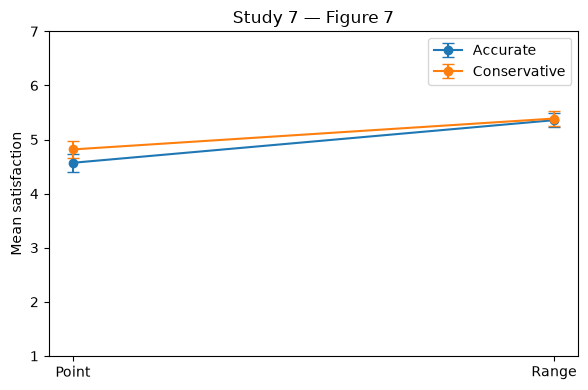

In [6]:
# Display group means and reproduce Figure 7 with 95% confidence intervals.
import matplotlib.pyplot as plt
summary = pd.DataFrame(descriptions).set_index('condition')
display(summary)
fig, ax = plt.subplots(figsize=(6,4))
for label, codes in [('Accurate',[1,3]),('Conservative',[2,4])]:
    q = summary.loc[codes]
    ax.errorbar([0,1],q['mean'],yerr=[q['mean']-q.ci_low,q.ci_high-q['mean']],marker='o',capsize=4,label=label)
ax.set(xticks=[0,1],xticklabels=['Point','Range'],ylim=(1,7),ylabel='Mean satisfaction',title='Study 7 — Figure 7')
ax.legend();fig.tight_layout();plt.show()